# $\zeta(3)$: historical constructions and new result

The CMF examples sample every 10 depths through depth 3000.
Each example prints its final $\delta_N$; the figure at the end plots
$\delta_N$ against $N$, where
$$D_N=-\log_{10}\left|\zeta(3)-\frac{p_N}{q_N}\right|,
\qquad \delta_N=\frac{D_N}{\log_{10}q_N}-1.$$
Here $p_N/q_N$ is reduced. Accuracy digits measure absolute approximation error.

Run the cells in order (Python 3.11+). The CMF encodings come from the supplied
exploratory notebooks and local supplementary material. Published bounds and the
finite-depth $\delta_N$ values are different quantities; the computations below do
not by themselves prove a published irrationality-measure bound.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.2

## Setup

Each example constructs a CMF, walks a trajectory with ramanujantools, reads
$p_N/q_N$ off the first column $(s_0,s_1,\ldots)$ of the walk, and computes
$\delta_N$. The walks and the approximants are exact.

In [2]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from ramanujantools import Position
from ramanujantools.cmf.meijer_g import MeijerG
from ramanujantools.cmf.pfq import pFq
from ramanujantools.flint_core.numeric_matrix import NumericMatrix

sys.set_int_max_str_digits(0)
with ctx.workdps(301_000):  # q_N reaches about 130,000 digits at depth 3000
    ZETA3 = arb(3).zeta()
    ZETA4 = arb(4).zeta()
    JOINT = 15 * ZETA3 + ZETA4
DEPTHS = list(range(10, 3001, 10))
n = sp.Symbol("n")
x0, x1, x2, x3, y0, y1, y2 = sp.symbols("x0 x1 x2 x3 y0 y1 y2")
a0, a1, a2, a3, b0, b1, b2, b3 = sp.symbols("a0:4 b0:4")
results = {}


def delta(approximant, value=ZETA3):
    """delta with |value - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |value - p/q|
        error = abs(value - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())

## 1. Apéry–Beukers (1978–1979)

F. Beukers, *A note on the irrationality of $\zeta(2)$ and $\zeta(3)$*,
Bull. London Math. Soc. **11** (1979), 268–272.
[Paper](https://doi.org/10.1112/blms/11.3.268).

**CMF:** ${}_4F_3(1)$ · **Start:** $(-2,-2,3,3;1,1,1)$ ·
**Direction:** $(-1,-1,1,1;0,0,0)$. We use the direct walk and the
extraction $p_N/q_N=(2106s_0+2683s_1)/(1752s_0+2232s_1)$.

In [3]:
cmf = pFq(4, 3, 1)
start = {x0: -2, x1: -2, x2: 3, x3: 3, y0: 1, y1: 1, y2: 1}
trajectory = {x0: -1, x1: -1, x2: 1, x3: 1, y0: 0, y1: 0, y2: 0}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(2106 * W[0, 0] + 2683 * W[1, 0]) / (1752 * W[0, 0] + 2232 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Apéry–Beukers (1978–1979)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.080614246


## 2. Hata (2000)

M. Hata, *A new irrationality measure for $\zeta(3)$*, Acta Arith.
**92** (2000), 47–57. The paper proves $\mu(\zeta(3))<7.377956$.

**CMF:** Meijer $G$ · **Start:** $(1,1,2,2;1,1,1,1)$ ·
**Direction:** $(0,1,15,16;8,7,8,9)$. We use the direct walk and the
extraction $p_N/q_N=s_1/(4s_0+2s_1)$.

In [4]:
cmf = MeijerG(4, 2, 4, 4, 1)
start = {a0: 1, a1: 1, a2: 2, a3: 2, b0: 1, b1: 1, b2: 1, b3: 1}
trajectory = {a0: 0, a1: 1, a2: 15, a3: 16, b0: 8, b1: 7, b2: 8, b3: 9}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / (4 * W[0, 0] + 2 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Hata (2000)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.156407426


## 3. Rhin–Viola (2001)

G. Rhin and C. Viola, *The group structure for $\zeta(3)$*,
Acta Arith. **97** (2001), 269–293.
[Paper](https://www.impan.pl/shop/en/publication/transaction/download/product/82430).
The paper proves $\mu(\zeta(3))<5.513891$.

**CMF:** Meijer $G$ · **Start:** $(1,1,2,2;1,1,1,1)$ ·
**Direction:** $(0,7,31,32;18,17,16,19)$. We use the direct walk and the
extraction $p_N/q_N=s_1/(4s_0+2s_1)$, as for Hata.

In [5]:
cmf = MeijerG(4, 2, 4, 4, 1)
start = {a0: 1, a1: 1, a2: 2, a3: 2, b0: 1, b1: 1, b2: 1, b3: 1}
trajectory = {a0: 0, a1: 7, a2: 31, a3: 32, b0: 18, b1: 17, b2: 16, b3: 19}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / (4 * W[0, 0] + 2 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Rhin–Viola (2001)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.221833369


## 4. New Meijer $G$ trajectory (this work)

The $\zeta(3)$ readout of the simultaneous $\zeta(3),\zeta(4)$ construction of
the paper (Section 6). The paper proves $\delta>0.22521567$ and
$\mu(\zeta(3))<5.44019$ for it.

**CMF:** Meijer $G$, $G^{5,2}_{5,5}(1)$ · **Start:** $(1,1,0,0,2;0,0,0,0,0)$ ·
**Direction:** $(11,12,-16,-17,10;0,1,2,-1,-2)$. We use the inverse-transpose
walk $(s_0,s_1,s_2,\ldots)$ and the extraction
$p_N/q_N=(-3s_1+3s_2)/(6s_2)$, the first and third rows of
$$\mathcal R_N=\begin{pmatrix}0&-3&3\\2&-2&0\\0&0&6\end{pmatrix}
\begin{pmatrix}s_0\\s_1\\s_2\end{pmatrix}.$$

In [6]:
cmf = MeijerG(5, 2, 5, 5, 1)
a = sp.symbols("a0:5")
b = sp.symbols("b0:5")
start = dict(zip(a + b, [1, 1, 0, 0, 2, 0, 0, 0, 0, 0]))
trajectory = dict(zip(a + b, [11, 12, -16, -17, 10, 0, 1, 2, -1, -2]))
# The dual walk is the inverse transpose of the walk, inverted numerically (FLINT).
matrix = cmf.trajectory_matrix(trajectory, start)
walks = NumericMatrix.walk(matrix, Position({n: 1}), DEPTHS, Position({n: 0}))
duals = [W.inv().transpose() for W in walks]
rows = [(-3 * D[1, 0] + 3 * D[2, 0], 2 * D[0, 0] - 2 * D[1, 0], 6 * D[2, 0]) for D in duals]
approximants = [p3 / q for p3, p4, q in rows]
deltas = [delta(r) for r in approximants]
results["New Meijer $G$ trajectory"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.226506885


## 5. Simultaneous approximations to $\zeta(3)$ and $\zeta(4)$

The same walk approximates $\zeta(4)$ through the second row of $\mathcal R_N$,
$p^{(4)}_N/q_N=(2s_0-2s_1)/(6s_2)$, with the same denominator. For a fixed
rational pair $(A,B)\ne(0,0)$ the readout of $A\zeta(3)+B\zeta(4)$ is
$(Ap^{(3)}_N+Bp^{(4)}_N)/q_N$. The paper proves $\delta>0.015629$ and
$\mu(A\zeta(3)+B\zeta(4))<64.983$ for every such pair, so $1,\zeta(3),\zeta(4)$
are linearly independent over $\mathbb Q$. Below we take $(A,B)=(15,1)$, the
combination ranked in the local neighbourhood search. Here
$\delta_N$ is measured against the target of each readout.

         ζ(3)  delta at depth 3000: 0.226506885
         ζ(4)  delta at depth 3000: 0.016253566
15ζ(3) + ζ(4)  delta at depth 3000: 0.016243417


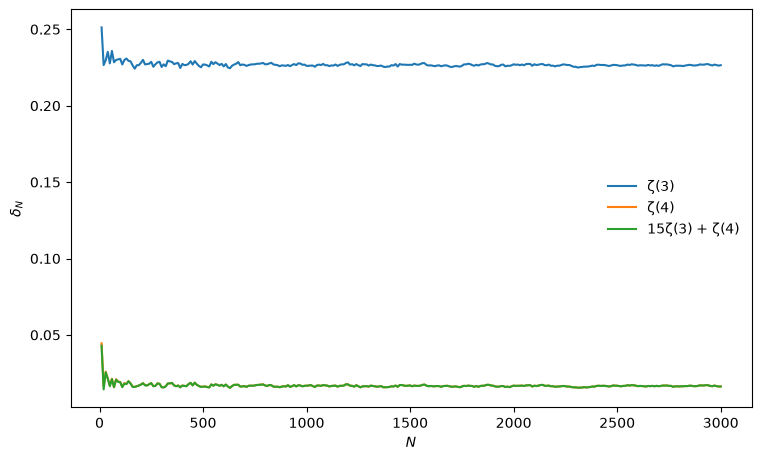

In [7]:
joint_results = {
    "ζ(3)": (DEPTHS, deltas),
    "ζ(4)": (DEPTHS, [delta(p4 / q, ZETA4) for p3, p4, q in rows]),
    "15ζ(3) + ζ(4)": (DEPTHS, [delta((15 * p3 + p4) / q, JOINT) for p3, p4, q in rows]),
}
for name, (depths, values) in joint_results.items():
    print(f"{name:>13}  delta at depth 3000: {values[-1]:.9f}")

fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in joint_results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Reconstruction attempt: Dvornicich–Viola (1987)

**Status: integral identified; multidimensional CMF unresolved.**
The construction on p. 650 of
[the original paper](https://mek.oszk.hu/24100/24107/pdf/24107_2.pdf)
uses $R(t)=t^{2k}(1-34t)^{2n}(1-35t)^{2m}$.
Here $k=\lfloor\lambda m\rfloor$, $n=\lfloor\nu m\rfloor$;
the calculation uses the printed rounded values $(\lambda,\nu)=(56.41,1.342)$.

For $\zeta(3)$, set
$$f(x,y,z)=\frac{x(1-x)y(1-y)z(1-z)}{1-(1-xy)z},\qquad
J_\ell=\int_{[0,1]^3}\frac{f(x,y,z)^\ell}{1-(1-xy)z}\,dx\,dy\,dz.$$
The exact recurrence starts with $J_0=2\zeta(3)$ and
$J_1=10\zeta(3)-12$:
$$(\ell+1)^3J_{\ell+1}-(34\ell^3+51\ell^2+27\ell+5)J_\ell
+\ell^3J_{\ell-1}=0.$$

If $(1-ct)^{2n}(1-dt)^{2m}=\sum_j r_jt^j$, the new integral is exactly
$\sum_jr_jJ_{2k+j}$. This finite sum does not give a fixed-size CMF with independent shifts in
$(k,n,m)$, so the construction is not encoded here.


### Hata (1990): integral identified, CMF still unresolved

Theorem 5.3 of [Hata's paper](https://doi.org/10.1515/crll.1990.407.99)
uses two Legendre-type polynomials and a rational correction to its triple
integral. On the subsequence $n=9N$, integration by parts gives the
following small linear form, up to the explicit factorial/divisor
normalization in that proof:
$$\int_{[0,1]^3}
\frac{x^{8N}(1-x)^{10N}y^{7N}(1-y)^{9N}v^{8N}(1-v)^{9N}}
{[1-x(1-v)]^{9N+1}(1-yv)^{8N+1}}\,dx\,dy\,dv.$$
Integrating $x,y$ expresses it as the beta-normalized convolution
$$B(8N+1,10N+1)B(7N+1,9N+1)
\int_0^1v^{8N}(1-v)^{9N}
{}_2F_1(9N+1,8N+1;18N+2;1-v)
{}_2F_1(8N+1,7N+1;16N+2;v)\,dv.$$
This supplies a concrete starting kernel for a larger field. A commuting
set of rational shift matrices and the corrected rational extraction have
not yet been constructed, so the historical row remains unverified.


## All constructions

$\delta_N$ against the walk depth $N$.

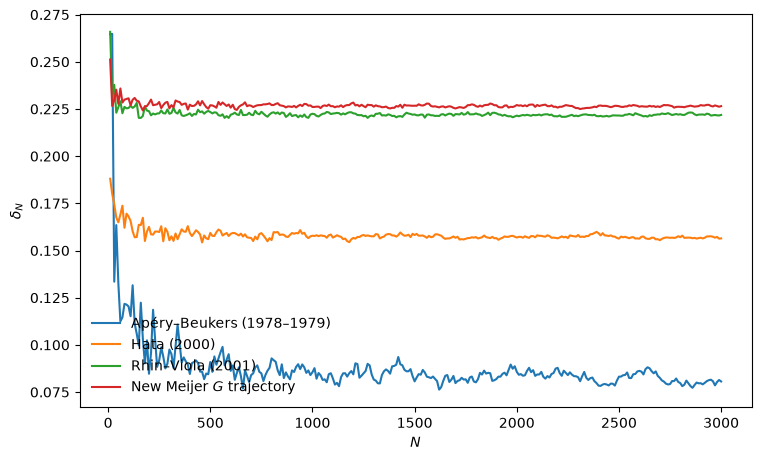

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Historical overview

| Construction | Published upper bound | Notebook coverage |
|:--|--:|:--|
| Apéry (1978) / Beukers (1979) | $13.41782$ | CMF above |
| Dvornicich–Viola (1987) | $12.7436$ | Integral reconstructed above; CMF unresolved |
| Hata (1990) | $8.83028$ | Integral identified above; CMF unresolved |
| Hata (2000) | $7.377956$ | CMF above |
| Rhin–Viola (2001) | $5.513891$ | CMF above |
| Giraudin (2026) | $5.5138800$ | reference only |
| This work: $\zeta(3)$ | $5.44019$ | CMF above |
| This work: $A\zeta(3)+B\zeta(4)$ | $64.983$ | Same CMF above |

The earlier bounds are summarized in the introduction to
[Rhin–Viola (2001)](https://www.impan.pl/shop/en/publication/transaction/download/product/82430).
Rows marked “reference only” have no verified CMF encoding in the supplied material.